In [1]:
import numpy as np
import pandas as pd
import joblib
from astroquery.gaia import Gaia
from kineamtics_and_dynamics import UVW, gal_population, compute_orbit_params


The archive is unstable and may perform below expectations. Please avoid launching intense Python query showers. Please contact the Gaia helpdesk in case of questions (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk). Workaround solutions for the issues following the recent infrastructure upgrade: https://www.cosmos.esa.int/web/gaia/news#WorkaroundArchive


In [ ]:
SWEETCAT_URL = 'https://sweetcat.iastro.pt/catalog/SWEETCAT_Dataframe.csv'

sweetcat = pd.read_csv(SWEETCAT_URL, low_memory=False)
sweetcat['source_id'] = pd.to_numeric(sweetcat['gaia_dr3'], errors='coerce').astype('Int64').astype('string')
sweetcat = sweetcat.rename(columns={
    '[Fe/H]': 'fe_h_sweetcat',
    'e[Fe/H]': 'e_fe_h_sweetcat',
    'Name': 'sweetcat_name',
})

keep_cols = [
    column for column in ['source_id', 'sweetcat_name', 'fe_h_sweetcat', 'e_fe_h_sweetcat', 'SWFlag']
    if column in sweetcat.columns
]
sweetcat = sweetcat[keep_cols].dropna(subset=['source_id']).drop_duplicates(subset='source_id').copy()
sweetcat.head()


,source_id,sweetcat_name,fe_h_sweetcat,e_fe_h_sweetcat,Reference
0,3946945413106333696,11 Com,-0.26,0.02,Sousa et al. 2021
1,1696798367260229376,11 UMi,-0.05,0.04,Sousa et al. 2021
2,1920113512486282240,14 And,-0.28,0.03,Sousa et al. 2021
3,1385293808145621504,14 Her,0.37,0.04,Sousa et al. 2021
4,2135550755683407232,16 Cyg B,0.09,0.02,Sousa et al. 2021


In [3]:
GAIA_COLUMNS = [
    'source_id', 'ra', 'dec', 'parallax', 'parallax_error',
    'pmra', 'pmdec', 'radial_velocity',
    'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag',
    'mh_gspphot', 'mh_gspspec',
]

KINEMATIC_COLUMNS = [
    'U_lsr', 'V_lsr', 'W_lsr', 'P_gal',
    'rapo', 'rperi', 'eccentricity', 'zmax',
]

def fetch_gaia_sources(source_ids, chunk_size=500, verbose=True):
    unique_ids = pd.Series(source_ids, dtype='string').dropna().astype(str).str.strip()
    unique_ids = unique_ids[unique_ids.ne('')].drop_duplicates().tolist()

    frames = []
    for start in range(0, len(unique_ids), chunk_size):
        batch = unique_ids[start:start + chunk_size]
        query_ids = ', '.join(batch)
        query = f"""
        SELECT gs.source_id, gs.ra, gs.dec, gs.parallax, gs.parallax_error,
               gs.pmra, gs.pmdec, gs.radial_velocity,
               gs.phot_g_mean_mag, gs.phot_bp_mean_mag, gs.phot_rp_mean_mag,
               ap.mh_gspphot, ap.mh_gspspec
        FROM gaiadr3.gaia_source AS gs
        LEFT JOIN gaiadr3.astrophysical_parameters AS ap USING (source_id)
        WHERE gs.source_id IN ({query_ids})
        """

        if verbose:
            stop = min(start + chunk_size, len(unique_ids))
            print(f'Querying Gaia rows {start + 1}-{stop} of {len(unique_ids)} source IDs')

        job = Gaia.launch_job_async(query)
        frame = job.get_results().to_pandas()
        frame['source_id'] = frame['source_id'].astype(str)
        frames.append(frame)

    if not frames:
        return pd.DataFrame(columns=GAIA_COLUMNS)

    gaia_results = pd.concat(frames, ignore_index=True)
    gaia_results = gaia_results.drop_duplicates(subset='source_id').reset_index(drop=True)
    return gaia_results

def get_first_available(row, candidates):
    for column in candidates:
        if column in row.index and pd.notna(row[column]):
            return row[column]
    return np.nan

def compute_row_kinematics(row):
    ra = get_first_available(row, ['ra_gaia', 'ra', 'ra_y', 'ra_x'])
    dec = get_first_available(row, ['dec_gaia', 'dec', 'dec_y', 'dec_x'])
    pmra = get_first_available(row, ['pmra'])
    pmdec = get_first_available(row, ['pmdec'])
    radial_velocity = get_first_available(row, ['radial_velocity'])
    parallax = get_first_available(row, ['parallax'])

    required_values = [ra, dec, pmra, pmdec, radial_velocity, parallax]
    if any(pd.isna(value) for value in required_values) or parallax <= 0:
        return pd.Series({column: np.nan for column in KINEMATIC_COLUMNS}, dtype=float)

    U_lsr, V_lsr, W_lsr = UVW(
        ra=ra,
        dec=dec,
        pmra=pmra,
        pmdec=pmdec,
        vrad=radial_velocity,
        plx=parallax,
        warnings=False,
    )
    P_gal = gal_population(U_lsr, V_lsr, W_lsr, char_vel='Mean')[0]
    orbit = compute_orbit_params(
        RA=ra,
        Dec=dec,
        plx=parallax,
        pmRA=pmra,
        pmDec=pmdec,
        Vlos=radial_velocity,
    )

    return pd.Series({
        'U_lsr': U_lsr,
        'V_lsr': V_lsr,
        'W_lsr': W_lsr,
        'P_gal': P_gal,
        'rapo': orbit['rapo'],
        'rperi': orbit['rperi'],
        'eccentricity': orbit['eccentricity'],
        'zmax': orbit['zmax'],
    }, dtype=float)

def add_kinematic_columns(df, progress_every=250):
    rows = []
    for idx, (_, row) in enumerate(df.iterrows(), start=1):
        if progress_every and idx % progress_every == 0:
            print(f'Computed kinematics for {idx} rows')
        rows.append(compute_row_kinematics(row))

    kinematics = pd.DataFrame(rows, index=df.index)
    kinematics = kinematics.apply(pd.to_numeric, errors='coerce')
    return pd.concat([df, kinematics], axis=1)


In [4]:
gaia_results = fetch_gaia_sources(sweetcat['source_id'], chunk_size=500)
gaia_results.head()


Querying Gaia rows 1-500 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 501-1000 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 1001-1500 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 1501-2000 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 2001-2500 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 2501-3000 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 3001-3500 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 3501-4000 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia rows 4001-4284 of 4284 source IDs
INFO: Query finished. [astroquery.utils.tap.core]


,source_id,ra,dec,parallax,parallax_error,pmra,pmdec,radial_velocity,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,mh_gspphot,mh_gspspec
0,101040381244467968,34.293343,23.767649,7.109225,0.021130,-32.316504,-40.891541,-11.840298,6.249009,6.770162,5.571686,-0.0653,-0.24
1,324889227693298560,35.383502,32.246041,3.974717,0.013384,47.671466,-21.593522,-19.845474,12.294833,12.737121,11.686585,-0.1151,0.39
2,351537889154226816,34.198018,43.772181,21.187662,0.025102,98.570189,-183.407710,30.648163,7.468568,7.774533,6.993208,-0.2129,-0.02
3,1506159170017461888,213.143854,47.014784,2.870509,0.014428,-29.620876,11.127044,-34.506905,12.963092,13.382845,12.386662,0.3661,NaN
4,1541532207133249920,188.266203,44.915368,3.405544,0.011038,-11.621530,8.138317,-16.775816,12.085042,12.440286,11.569020,0.3156,0.10


In [ ]:
sweetcat_merged = sweetcat.merge(
    gaia_results,
    on='source_id',
    how='left',
    validate='m:1',
    suffixes=('_sweetcat', '_gaia'),
)

sweetcat_with_kinematics = add_kinematic_columns(sweetcat_merged)
sweetcat_with_kinematics.to_csv('sweetcat_gaia_with_kinematics.csv', index=False)
sweetcat_with_kinematics[['source_id', 'fe_h_sweetcat'] + KINEMATIC_COLUMNS].head()


In [ ]:
abundance_models = {
    'mg_h_pred': joblib.load('models/lgbm_model_mg_h.joblib'),
    'si_h_pred': joblib.load('models/lgbm_model_si_h.joblib'),
    'o_h_pred': joblib.load('models/lgbm_model_o_h.joblib'),
    'c_h_pred': joblib.load('models/lgbm_model_c_h.joblib'),
}

ABUNDANCE_FEATURES = list(next(iter(abundance_models.values())).feature_name_)

sweetcat_predictions = sweetcat_with_kinematics.copy()
sweetcat_predictions[KINEMATIC_COLUMNS] = sweetcat_predictions[KINEMATIC_COLUMNS].apply(pd.to_numeric, errors='coerce')
sweetcat_predictions['fe_h_sweetcat'] = pd.to_numeric(sweetcat_predictions['fe_h_sweetcat'], errors='coerce')
sweetcat_predictions['fe_h_input_abund'] = sweetcat_predictions['fe_h_sweetcat']
sweetcat_predictions['fe_h'] = sweetcat_predictions['fe_h_input_abund']

X_abund = sweetcat_predictions[ABUNDANCE_FEATURES].copy()
valid_abundance_rows = X_abund.notna().all(axis=1)

for output_column, model in abundance_models.items():
    sweetcat_predictions[output_column] = np.nan
    sweetcat_predictions.loc[valid_abundance_rows, output_column] = model.predict(
        X_abund.loc[valid_abundance_rows]
    )

sweetcat_predictions.to_csv('sweetcat_gaia_predicted_abundances.csv', index=False)
sweetcat_predictions[
    ['source_id', 'fe_h_sweetcat', 'mg_h_pred', 'si_h_pred', 'o_h_pred', 'c_h_pred']
].head()


In [ ]:
SOLAR_ABUNDANCES = {
    'c': 8.46,
    'o': 8.69,
    'mg': 7.55,
    'si': 7.51,
    'fe': 7.46,
}

RATIO_SPECS = {
    'fe_si': {'numerator': 'fe', 'denominator': 'si', 'num_col': 'fe_h', 'den_col': 'si_h_pred'},
    'mg_si': {'numerator': 'mg', 'denominator': 'si', 'num_col': 'mg_h_pred', 'den_col': 'si_h_pred'},
    'c_o': {'numerator': 'c', 'denominator': 'o', 'num_col': 'c_h_pred', 'den_col': 'o_h_pred'},
    'fe_o': {'numerator': 'fe', 'denominator': 'o', 'num_col': 'fe_h', 'den_col': 'o_h_pred'},
}

def add_linear_ratio_columns(df):
    df = df.copy()
    for key, spec in RATIO_SPECS.items():
        log_ratio = df[spec['num_col']] - df[spec['den_col']]
        solar_offset = SOLAR_ABUNDANCES[spec['numerator']] - SOLAR_ABUNDANCES[spec['denominator']]
        df[f'linear_{key}'] = 10 ** (log_ratio + solar_offset)
    return df

sweetcat_predictions = add_linear_ratio_columns(sweetcat_predictions)
sweetcat_predictions.to_csv('sweetcat_gaia_predicted_abundances_and_ratios.csv', index=False)
sweetcat_predictions[
    ['source_id', 'fe_h_sweetcat', 'linear_fe_si', 'linear_mg_si', 'linear_c_o', 'linear_fe_o']
].head()


In [ ]:
linear_ratio_fit_summary = pd.read_csv('figures/ratio_fits/linear_ratio_fit_summary.csv')
linear_ratio_fit_summary[['survey', 'ratio_key', 'ratio', 'equation', 'rms_scatter']]


In [ ]:
for _, fit_row in linear_ratio_fit_summary.iterrows():
    fit_column = f"{fit_row['ratio_key']}_fit_{fit_row['survey'].lower()}"
    residual_column = f"linear_{fit_row['ratio_key']}_minus_{fit_row['survey'].lower()}_fit"
    sweetcat_predictions[fit_column] = fit_row['intercept'] + fit_row['slope'] * sweetcat_predictions['fe_h_sweetcat']
    sweetcat_predictions[residual_column] = sweetcat_predictions[f"linear_{fit_row['ratio_key']}"] - sweetcat_predictions[fit_column]

sweetcat_predictions.to_csv('sweetcat_gaia_predicted_abundances_and_ratios_with_fits.csv', index=False)
sweetcat_predictions[
    [
        'source_id', 'fe_h_sweetcat',
        'linear_fe_si', 'fe_si_fit_apogee', 'fe_si_fit_harps',
        'linear_mg_si', 'mg_si_fit_apogee', 'mg_si_fit_harps',
        'linear_c_o', 'c_o_fit_apogee', 'c_o_fit_harps',
        'linear_fe_o', 'fe_o_fit_apogee', 'fe_o_fit_harps',
    ]
].head()


In [ ]:
ratio_comparison_rows = []
for ratio_key in RATIO_SPECS:
    predicted_col = f'linear_{ratio_key}'
    for survey in ['apogee', 'harps']:
        fit_col = f'{ratio_key}_fit_{survey}'
        comp = sweetcat_predictions[['source_id', 'fe_h_sweetcat', predicted_col, fit_col]].dropna().copy()
        comp['residual'] = comp[predicted_col] - comp[fit_col]
        ratio_comparison_rows.append({
            'ratio_key': ratio_key,
            'survey_fit': survey.upper(),
            'n_stars': len(comp),
            'mean_predicted_ratio': comp[predicted_col].mean(),
            'mean_fit_ratio': comp[fit_col].mean(),
            'mean_residual': comp['residual'].mean(),
            'std_residual': comp['residual'].std(),
            'mae_residual': comp['residual'].abs().mean(),
        })

ratio_fit_comparison_summary = pd.DataFrame(ratio_comparison_rows)
ratio_fit_comparison_summary.to_csv('sweetcat_ratio_fit_comparison_summary.csv', index=False)
ratio_fit_comparison_summary


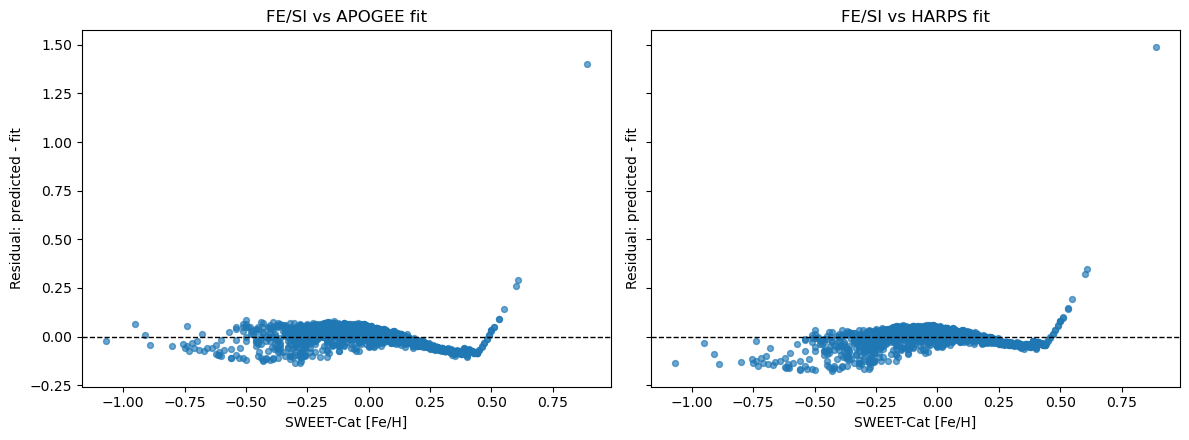

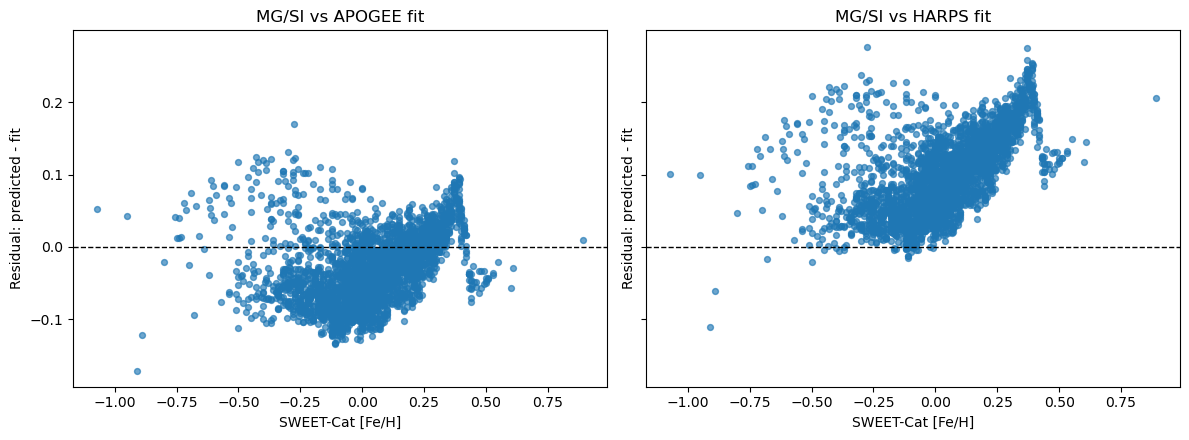

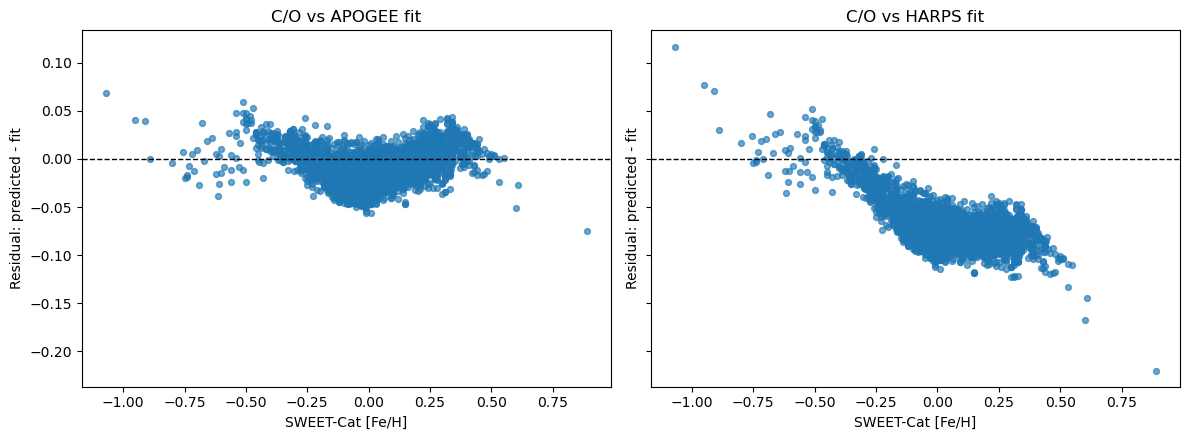

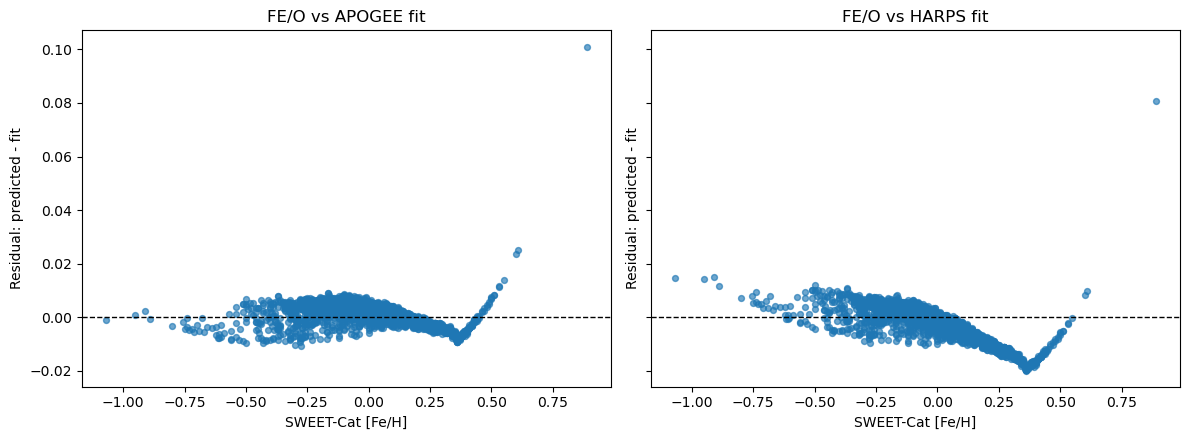

In [12]:
import matplotlib.pyplot as plt
from pathlib import Path

plot_dir = Path('figures/sweetcat_ratio_fit_residuals')
plot_dir.mkdir(parents=True, exist_ok=True)

for ratio_key, spec in RATIO_SPECS.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, survey in zip(axes, ['apogee', 'harps']):
        residual_col = f'linear_{ratio_key}_minus_{survey}_fit'
        comp = sweetcat_predictions[['fe_h_sweetcat', residual_col]].dropna().copy()

        ax.scatter(comp['fe_h_sweetcat'], comp[residual_col], s=18, alpha=0.65)
        ax.axhline(0.0, color='black', linestyle='--', linewidth=1)
        ax.set_xlabel('SWEET-Cat [Fe/H]')
        ax.set_ylabel('Residual: predicted - fit')
        ax.set_title(f"{spec['numerator'].upper()}/{spec['denominator'].upper()} vs {survey.upper()} fit")

    plt.tight_layout()
    fig.savefig(plot_dir / f'{ratio_key}_residuals_vs_feh.png', dpi=200, bbox_inches='tight')
    plt.show()
